<a href="https://colab.research.google.com/github/Hafizh213/KKA3_ADV/blob/p/Teamwork6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Import Library dan Visualisasi Data

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# Unggah dataset CSV
uploaded = files.upload()
if not uploaded:
    raise ValueError("File CSV belum diunggah.")
nama_file = next(iter(uploaded))
df = pd.read_csv(nama_file)

# Pastikan kolom yang dibutuhkan tersedia
kolom_wajib = ["Stars", "Country", "Review #", "Style"]
kolom_hilang = [kolom for kolom in kolom_wajib if kolom not in df.columns]
if kolom_hilang:
    raise ValueError(f"Kolom berikut tidak ditemukan: {kolom_hilang}")

print("Preview data:")
display(df.head())
print("\nInformasi data:")
df.info()
print("\nJumlah nilai kosong:")
print(df.isnull().sum())
print("\nJumlah baris duplikat:", df.duplicated().sum())

Saving ramen-ratings.csv to ramen-ratings (2).csv
Preview data:


,Review #,Brand,Variety,Style,Country,Stars,Top Ten
0,2580,New Touch,T's Restaurant Tantanmen,Cup,Japan,3.75,NaN
1,2579,Just Way,Noodles Spicy Hot Sesame Spicy Hot Sesame Guan...,Pack,Taiwan,1,NaN
2,2578,Nissin,Cup Noodles Chicken Vegetable,Cup,USA,2.25,NaN
3,2577,Wei Lih,GGE Ramen Snack Tomato Flavor,Pack,Taiwan,2.75,NaN
4,2576,Ching's Secret,Singapore Curry,Pack,India,3.75,NaN



Informasi data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2580 entries, 0 to 2579
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Review #  2580 non-null   int64 
 1   Brand     2580 non-null   object
 2   Variety   2580 non-null   object
 3   Style     2578 non-null   object
 4   Country   2580 non-null   object
 5   Stars     2580 non-null   object
 6   Top Ten   41 non-null     object
dtypes: int64(1), object(6)
memory usage: 141.2+ KB

Jumlah nilai kosong:
Review #       0
Brand          0
Variety        0
Style          2
Country        0
Stars          0
Top Ten     2539
dtype: int64

Jumlah baris duplikat: 0


Langkah pertama yaitu Import library menggunakan :
1. import pandas as pd
2. import matplotlib.pyplot as plt
3. import seaborn as sns
4. from google.colab import files

Lalu dilanjut dengan mencari informasi data menggunakan :
1. print("Preview data:")
   display(df.head())
2. print("\nInformasi data:")
   df.info()
3. print("\nJumlah nilai kosong:")
4. print(df.isnull().sum())
5. print("\nJumlah baris duplikat:", df.duplicated().sum())

In [ ]:
# Bersihkan rating yang bukan angka
df["Stars"] = pd.to_numeric(df["Stars"], errors="coerce")
data = df.dropna(subset=["Stars"]).copy()
print("Jumlah data dengan rating valid:", len(data))

# Statistik deskriptif
print("\nStatistika deskriptif:")
display(data["Stars"].describe())
print("Mean:", data["Stars"].mean())
print("Median:", data["Stars"].median())
print("Modus:", data["Stars"].mode().tolist())
print("Range:", data["Stars"].max() - data["Stars"].min())
print("Variansi:", data["Stars"].var())
print("Standar deviasi:", data["Stars"].std())
print("Q1:", data["Stars"].quantile(0.25))
print("Q3:", data["Stars"].quantile(0.75))

Jumlah data dengan rating valid: 2577

Statistika deskriptif:


,Stars
count,2577.000000
mean,3.654676
std,1.015331
min,0.000000
25%,3.250000
50%,3.750000
75%,4.250000
max,5.000000


Mean: 3.6546759798214974
Median: 3.75
Modus: [4.0]
Range: 5.0
Variansi: 1.0308962167869422
Standar deviasi: 1.0153305948246325
Q1: 3.25
Q3: 4.25


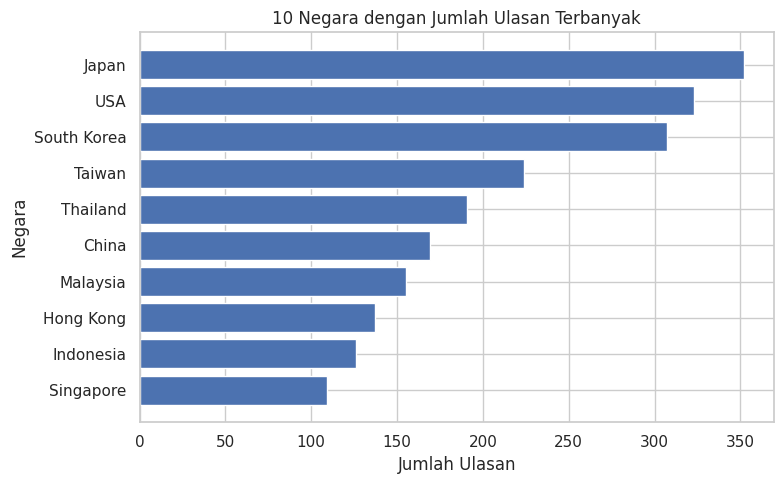

In [ ]:
# Bar Chart: 10 negara dengan jumlah ulasan terbanyak
negara = data.groupby("Country")["Stars"].count().sort_values(ascending=False).head(10)
plt.figure(figsize=(8, 5))
plt.barh(negara.index[::-1], negara.values[::-1])
plt.title("10 Negara dengan Jumlah Ulasan Terbanyak")
plt.xlabel("Jumlah Ulasan")
plt.ylabel("Negara")
plt.tight_layout()
plt.show()

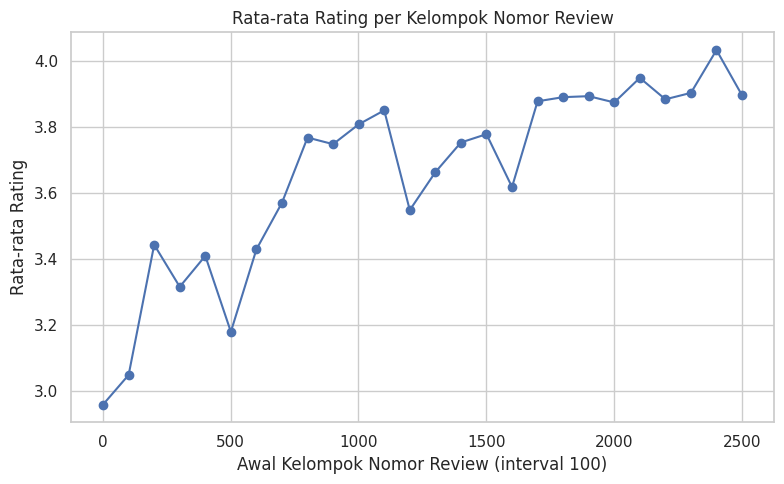

In [ ]:
# Line Chart: kelompok nomor review, bukan tren waktu karena tidak ada tanggal
urut = data.sort_values("Review #").copy()
urut["kelompok_review"] = ((pd.to_numeric(urut["Review #"], errors="coerce") - 1) // 100) * 100 + 1
urut = urut.dropna(subset=["kelompok_review"])
tren = urut.groupby("kelompok_review")["Stars"].mean()
plt.figure(figsize=(8, 5))
plt.plot(tren.index, tren.values, marker="o")
plt.title("Rata-rata Rating per Kelompok Nomor Review")
plt.xlabel("Awal Kelompok Nomor Review (interval 100)")
plt.ylabel("Rata-rata Rating")
plt.tight_layout()
plt.show()

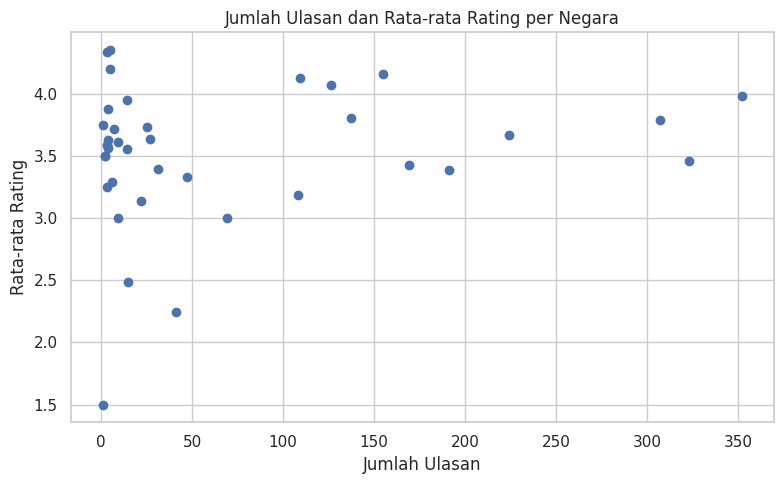

In [ ]:
# Scatter Plot: jumlah ulasan dan rata-rata rating per negara
negara_scatter = data.groupby("Country")["Stars"].agg(["count", "mean"]).reset_index()
plt.figure(figsize=(8, 5))
plt.scatter(negara_scatter["count"], negara_scatter["mean"])
plt.title("Jumlah Ulasan dan Rata-rata Rating per Negara")
plt.xlabel("Jumlah Ulasan")
plt.ylabel("Rata-rata Rating")
plt.tight_layout()
plt.show()

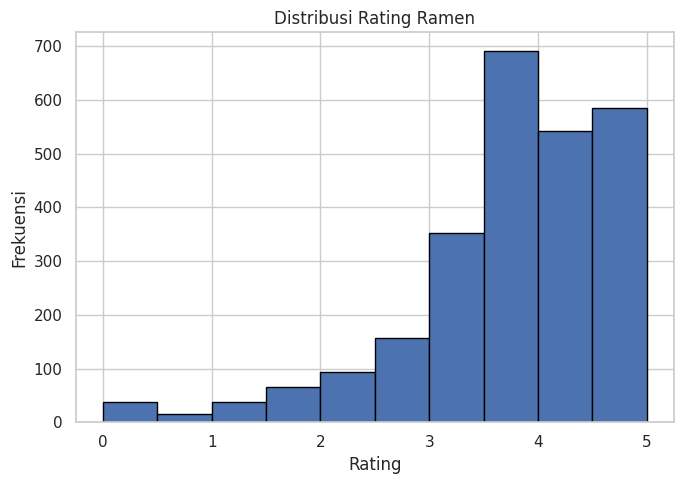

In [ ]:
# Histogram
plt.figure(figsize=(7, 5))
plt.hist(data["Stars"], bins=10, edgecolor="black")
plt.title("Distribusi Rating Ramen")
plt.xlabel("Rating")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

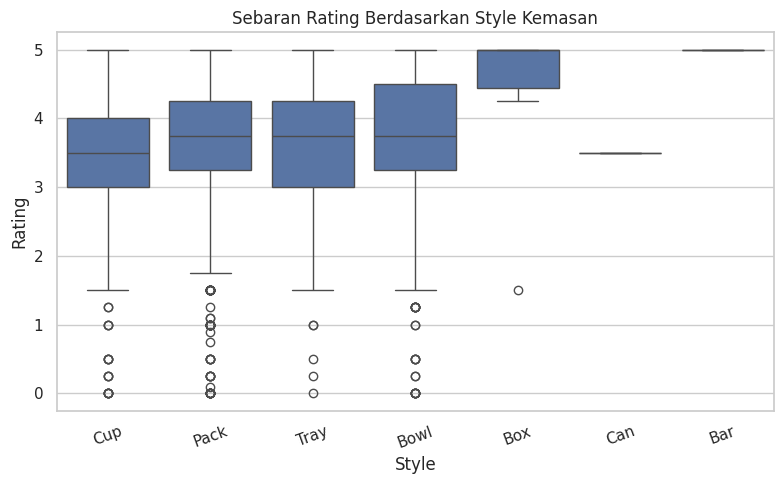

In [ ]:
# Boxplot rating berdasarkan style kemasan
plt.figure(figsize=(8, 5))
sns.boxplot(data=data, x="Style", y="Stars")
plt.title("Sebaran Rating Berdasarkan Style Kemasan")
plt.xlabel("Style")
plt.ylabel("Rating")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
# Deteksi outlier dengan metode IQR
q1 = data["Stars"].quantile(0.25)
q3 = data["Stars"].quantile(0.75)
iqr = q3 - q1
batas_bawah = q1 - 1.5 * iqr
batas_atas = q3 + 1.5 * iqr
outlier = data[(data["Stars"] < batas_bawah) | (data["Stars"] > batas_atas)]
print("Q1:", q1, "Q3:", q3, "IQR:", iqr)
print("Batas bawah:", batas_bawah, "Batas atas:", batas_atas)
print("Jumlah outlier:", len(outlier))
display(outlier.head())

Q1: 3.25 Q3: 4.25 IQR: 1.0
Batas bawah: 1.75 Batas atas: 5.75
Jumlah outlier: 129


,Review #,Brand,Variety,Style,Country,Stars,Top Ten
1,2579,Just Way,Noodles Spicy Hot Sesame Spicy Hot Sesame Guan...,Pack,Taiwan,1.00,NaN
8,2572,Ripe'n'Dry,Hokkaido Soy Sauce Ramen,Pack,Japan,0.25,NaN
36,2544,Lipton,Cup-A-Soup Chicken Noodle With White Meat Inst...,Box,USA,1.50,NaN
38,2542,Acecook,Super Cup Yochan Ika Yakisoba,Tray,Japan,1.50,NaN
53,2527,Uni-President,Mushroom Flavor,Pack,Vietnam,0.00,NaN


Perhitungan Rentang IQR: Menghitung Kuartil 1 (Q1), Kuartil 3 (Q3), dan nilai Interquartile Range (IQR) pada kolom Stars.Penentuan Batas Outlier: Menghitung batas bawah ($Q1 - 1.5 \times IQR$) dan batas atas ($Q3 + 1.5 \times IQR$) untuk mendeteksi nilai ekstrem.Penyaringan & Tampilan Outlier: Menyaring baris data rating yang berada di luar batas bawah/atas, lalu menampilkan jumlah total serta 5 baris pertama data outlier tersebut.

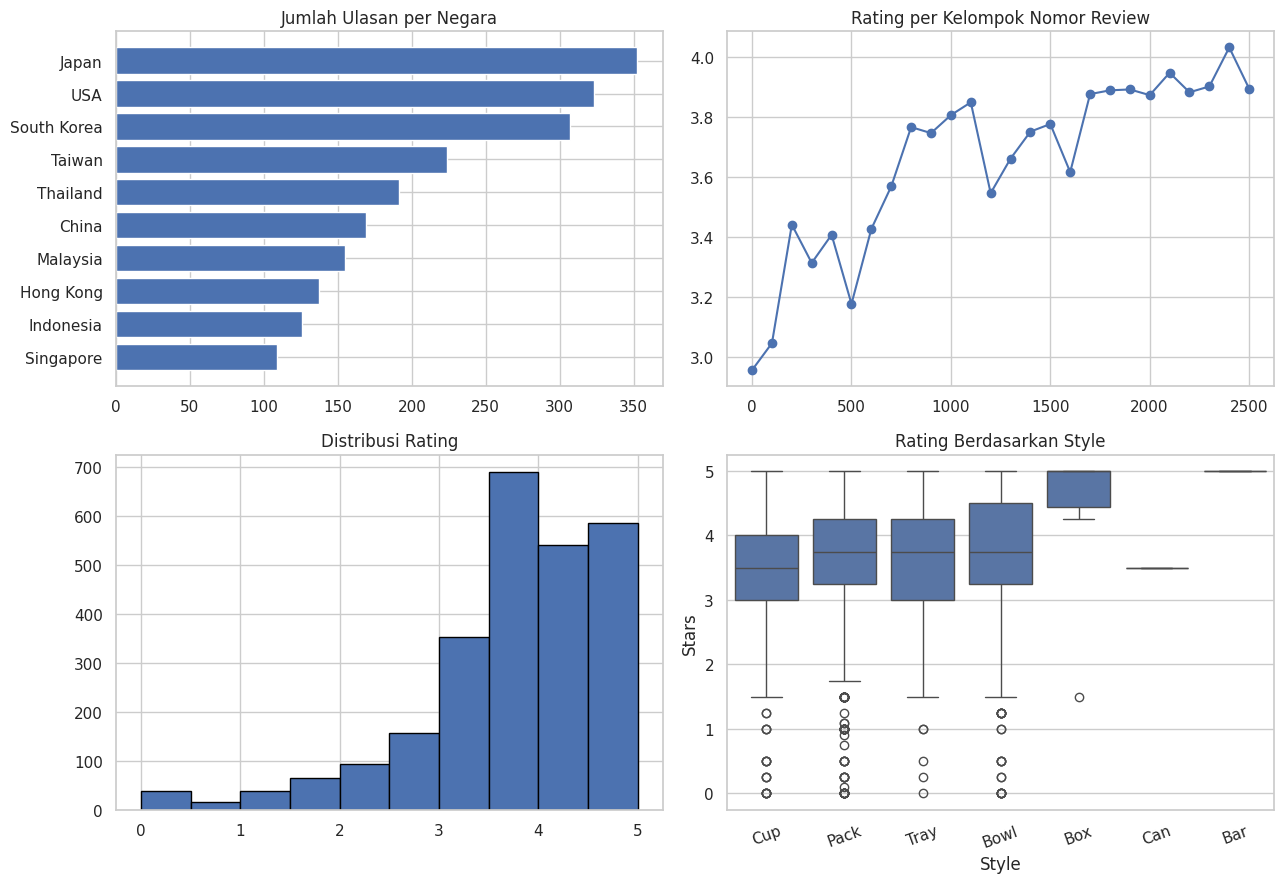

In [ ]:
# Dashboard 2x2
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Definisikan kembali 'negara' agar tidak terjadi NameError
negara = data.groupby("Country")["Stars"].count().sort_values(ascending=False).head(10)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes[0, 0].barh(negara.index[::-1], negara.values[::-1])
axes[0, 0].set_title("Jumlah Ulasan per Negara")
axes[1, 0].hist(data["Stars"], bins=10, edgecolor="black")
axes[1, 0].set_title("Distribusi Rating")
if not tren.empty:
    axes[0, 1].plot(tren.index, tren.values, marker="o")
axes[0, 1].set_title("Rating per Kelompok Nomor Review")
sns.boxplot(data=data, x="Style", y="Stars", ax=axes[1, 1])
axes[1, 1].set_title("Rating Berdasarkan Style")
axes[1, 1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

Groupby & Agregasi: Mengelompokkan ulang data berdasarkan negara (Country) untuk mengambil 10 negara dengan jumlah ulasan terbanyak.Membuat Grid Subplot 2x2: Menginisialisasi tata letak grafik 2x2 (plt.subplots(2, 2)) berukuran $13 \times 9$ inci untuk menampilkan 4 grafik sekaligus dalam satu tampilan dashboard.Pengisian Grafik ke Subplot:Kiri Atas [0,0]: Grafik batang horizontal jumlah ulasan per negara.Kanan Atas [0,1]: Grafik garis rata-rata rating per kelompok nomor ulasan.Kiri Bawah [1,0]: Histogram distribusi frekuensi rating.Kanan Bawah [1,1]: Boxplot sebaran rating berdasarkan tipe kemasan (Style).Kustomisasi & Tata Letak: Menambahkan judul pada tiap subplot, memutar label sumbu X boxplot sebesar 20 derajat, serta merapikan jarak antar-grafik (tight_layout).